# Experiment 2: Multimodal Fake Job Detection with Pretrained ResNet-50

## Overview

This notebook implements **Experiment 2** of the job-posting fraud detection research project.

**Experiment 1** used a custom Multi-Kernel ResNet image branch and achieved:
- Accuracy: 97.43%
- FAKE recall: 78.61%
- FAKE F1: 74.73%
- Confusion matrix: `[[3348, 55], [37, 136]]`

Experiment 1 had two key issues:
1. **Methodological bug**: The validation loader reused the training dataset (`val_loader = DataLoader(train_dataset, ...)`), producing misleading validation metrics.
2. **Weak image representation**: The custom Multi-Kernel ResNet was trained from scratch on a small dataset, limiting its visual feature quality.

**Experiment 2** addresses both issues:
1. **Fixes the validation split** with a genuine three-way stratified train/validation/test split.
2. **Replaces the custom image backbone** with a pretrained ResNet-50 using transfer learning.

The rest of the multimodal architecture (BERT, TF-IDF, BoW, fusion) remains conceptually comparable for fair comparison.

## Architecture

```
                         JOB POSTING
                              |
             +----------------+----------------+
             |                |                |
             v                v                v
        Job Description    Screenshot       Text Features
             |                |                |
             v                v                |
           BERT        Pre-trained ResNet-50   |
             |                |                |
             v                v                v
        BERT Features   Image Features    TF-IDF + BoW
             |                |                |
             +----------------+----------------+
                              |
                              v
                     Multimodal Fusion
                              |
                              v
                       Classification
                              |
                       +------+------+
                       |             |
                    GENUINE        FAKE
```

## 2. Experiment 2 Objective

**Primary goal**: Determine whether replacing the custom Multi-Kernel ResNet image branch with a pretrained ResNet-50 transfer-learning branch improves fraudulent-job detection.

**Key metrics to compare against Experiment 1**:
1. **FAKE recall** — Are fewer fraudulent jobs missed?
2. **FAKE F1** — Is the balance between precision and recall better?
3. **False negatives** — Are fewer fraudulent jobs classified as genuine?

**Secondary goal**: Fix the validation split methodology to ensure honest model evaluation.

**What stays the same** (for fair comparison):
- BERT branch (frozen, bert-base-uncased)
- TF-IDF branch (1000 features)
- BoW branch (500 features)
- Multimodal fusion architecture concept
- Same dataset, same class mapping (0=GENUINE, 1=FAKE)

**What changes**:
- Image backbone: Custom ResNet → Pretrained ResNet-50
- Validation: Leaky split → Genuine three-way split
- Monitoring: Validation loss → Validation FAKE F1
- Evaluation: Basic metrics → Comprehensive FAKE-focused analysis

> **Important**: This notebook contains executable code but is NOT executed automatically. All cells are provided for manual execution. No model training, inference, or evaluation is performed by the notebook builder.

## 3. Imports and Configuration

All libraries, paths, and hyperparameters are defined in one place for easy modification.

In [1]:
# ============================================================
# SECTION 3: IMPORTS AND CONFIGURATION
# ============================================================

import os
import time
import warnings
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_fscore_support
)
from sklearn.utils.class_weight import compute_class_weight

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image

from transformers import BertModel, BertTokenizer

warnings.filterwarnings("ignore")

# ============================================================
# CONFIGURATION — all paths and hyperparameters in one place
# ============================================================

# --- Data paths ---
DATA_PATH = r"C:\DEV\Fake Job Prediction\Fake Job Dataset\fake_job_postings.csv"
IMAGE_BASE_PATH = r"C:\DEV\Fake Job Prediction\Fake Job Dataset\images"

# --- BERT ---
BERT_MODEL_NAME = "bert-base-uncased"
BERT_MAX_LEN = 256

# --- Text features ---
TFIDF_MAX_FEATURES = 1000
TFIDF_NGRAM_RANGE = (1, 2)
BOW_MAX_FEATURES = 500

# --- Model architecture ---
DROPOUT_RATE = 0.4
IMAGE_SIZE = 224
BERT_OUT_DIM = 768       # BERT hidden size
RESNET_OUT_DIM = 2048    # ResNet-50 feature dimension

# --- Projection dimensions ---
BERT_PROJ_DIM = 256
TFIDF_PROJ_DIM = 256
BOW_PROJ_DIM = 128
IMG_PROJ_DIM = 256
FUSION_DIM = BERT_PROJ_DIM + TFIDF_PROJ_DIM + BOW_PROJ_DIM + IMG_PROJ_DIM  # 896

# --- Training ---
BATCH_SIZE = 8
NUM_EPOCHS = 20
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 0.01
MAX_GRAD_NORM = 1.0
EARLY_STOP_PATIENCE = 5
AUXILIARY_LOSS_WEIGHT = 0.2

# --- Class mapping ---
CLASS_NAMES = {0: "GENUINE", 1: "FAKE"}
CLASS_MAPPING = {"GENUINE": 0, "FAKE": 1}

# --- ImageNet normalization ---
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# --- Checkpoint ---
CHECKPOINT_PATH = r"C:\DEV\FAKE ML\Experiment_2\best_experiment2_model.pth"

print("All imports loaded successfully.")
print(f"Data path:      {DATA_PATH}")
print(f"Image base:     {IMAGE_BASE_PATH}")
print(f"Checkpoint:     {CHECKPOINT_PATH}")
print(f"Device:         {'cuda' if torch.cuda.is_available() else 'cpu'}")
if torch.cuda.is_available():
    print(f"GPU:            {torch.cuda.get_device_name(0)}")

All imports loaded successfully.
Data path:      C:\DEV\Fake Job Prediction\Fake Job Dataset\fake_job_postings.csv
Image base:     C:\DEV\Fake Job Prediction\Fake Job Dataset\images
Checkpoint:     C:\DEV\FAKE ML\Experiment_2\best_experiment2_model.pth
Device:         cuda
GPU:            NVIDIA GeForce RTX 3050 6GB Laptop GPU


## 4. Reproducibility / Random Seeds

All random seeds are set to ensure reproducible results across runs.

In [3]:
# ============================================================
# SECTION 4: REPRODUCIBILITY
# ============================================================

SEED = 42

def set_seed(seed):
    '''Set all random seeds for reproducibility.'''
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

# Device selection
# Device selection
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Seed set to: {SEED}")
print(f"Device: {device}")

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    mem = torch.cuda.get_device_properties(0).total_memory / 1024**3
    print(f"GPU Memory: {mem:.2f} GB")

Seed set to: 42
Device: cuda
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
GPU Memory: 6.00 GB


## 5. Dataset Loading

Load the CSV dataset and map each job posting to its corresponding screenshot image path.

In [4]:
# ============================================================
# SECTION 5: DATASET LOADING
# ============================================================

df = pd.read_csv(DATA_PATH)

# Map each job posting to its webpage screenshot
df["webpage_screenshot"] = df.apply(
    lambda row: os.path.join(
        IMAGE_BASE_PATH,
        str(row["fraudulent"]),
        f"{row['job_id']}.png"
    ),
    axis=1
)

print(f"Dataset loaded: {df.shape[0]} rows, {df.shape[1]} columns")
display(df.head())

Dataset loaded: 17880 rows, 19 columns


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent,webpage_screenshot
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0,C:\DEV\Fake Job Prediction\Fake Job Dataset\im...
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0,C:\DEV\Fake Job Prediction\Fake Job Dataset\im...
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0,C:\DEV\Fake Job Prediction\Fake Job Dataset\im...
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0,C:\DEV\Fake Job Prediction\Fake Job Dataset\im...
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0,C:\DEV\Fake Job Prediction\Fake Job Dataset\im...


## 6. Dataset Inspection

Examine dataset structure, missing values, and class distribution.

=== Dataset Info ===
Shape: (17880, 19)
Columns: ['job_id', 'title', 'location', 'department', 'salary_range', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent', 'webpage_screenshot']

=== Missing Values (top 10) ===


salary_range           15012
department             11547
required_education      8105
benefits                7212
required_experience     7050
function                6455
industry                4903
employment_type         3471
company_profile         3308
requirements            2696
dtype: int64


=== Target Distribution ===
  GENUINE (0): 17,014 (95.16%)
  FAKE (1): 866 (4.84%)


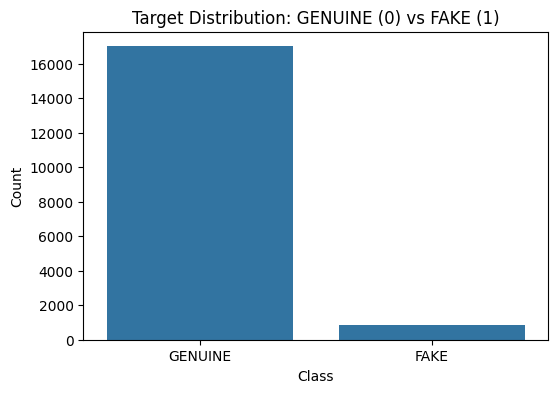


Dataset has 866 fraudulent postings out of 17880 total.
Class ratio: 19.6:1 (GENUINE:FAKE)


In [5]:
# ============================================================
# SECTION 6: DATASET INSPECTION
# ============================================================

print("=== Dataset Info ===")
print(f"Shape: {df.shape}")
print(f"Columns: {list(df.columns)}")

print("\n=== Missing Values (top 10) ===")
missing = df.isnull().sum().sort_values(ascending=False)
display(missing[missing > 0].head(10))

print("\n=== Target Distribution ===")
dist = df["fraudulent"].value_counts()
pct = df["fraudulent"].value_counts(normalize=True) * 100
for label in [0, 1]:
    print(f"  {CLASS_NAMES[label]} ({label}): {dist[label]:,} ({pct[label]:.2f}%)")

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="fraudulent")
plt.title("Target Distribution: GENUINE (0) vs FAKE (1)")
plt.xlabel("Class")
plt.ylabel("Count")
plt.xticks([0, 1], ["GENUINE", "FAKE"])
plt.show()

print(f"\nDataset has {df['fraudulent'].sum()} fraudulent postings out of {len(df)} total.")
print(f"Class ratio: {dist[0]/dist[1]:.1f}:1 (GENUINE:FAKE)")

## 7. Data Cleaning

Combine all text fields into a single `text` column and analyze word counts.

In [6]:
# ============================================================
# SECTION 7: DATA CLEANING
# ============================================================

text_columns = [
    "title", "location", "department", "company_profile",
    "description", "requirements", "benefits"
]

# Merge text fields (NaN → empty string)
df["text"] = df[text_columns].fillna("").agg(" ".join, axis=1)

# Word count analysis
df["word_count"] = df["text"].str.split().str.len()

print("Combined text column created.")
print(f"Average word count: {df['word_count'].mean():.1f}")
print(f"Median word count:  {df['word_count'].median():.1f}")

print("\n=== Word Count by Class ===")
for label in [0, 1]:
    subset = df[df["fraudulent"] == label]
    print(f"  {CLASS_NAMES[label]}: mean={subset['word_count'].mean():.1f}, "
          f"median={subset['word_count'].median():.1f}, "
          f"min={subset['word_count'].min()}, max={subset['word_count'].max()}")

# Verify screenshot existence
existing = df["webpage_screenshot"].apply(os.path.exists).sum()
print(f"\nScreenshots found: {existing}/{len(df)} ({existing/len(df)*100:.1f}%)")

Combined text column created.
Average word count: 378.4
Median word count:  353.0

=== Word Count by Class ===
  GENUINE: mean=383.1, median=358.0, min=8, max=2121
  FAKE: mean=286.0, median=230.5, min=4, max=1343

Screenshots found: 17796/17880 (99.5%)


## 8. Train / Validation / Test Split

**Critical fix from Experiment 1**: The validation set must be genuinely separate from the training set.

Strategy:
1. First split: 80% train+val, 20% test (test held out permanently)
2. Second split: Within the 80%, split into ~80% train and ~20% validation
3. All splits are stratified on the fraud label

**Final approximate sizes**: ~70% train, ~10% validation, ~20% test

In [7]:
# ============================================================
# SECTION 8: TRAIN / VALIDATION / TEST SPLIT
# ============================================================

# Step 1: Separate test set (20%)
train_val_df, test_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["fraudulent"],
    random_state=SEED
)

# Step 2: Separate validation from training (within the 80%)
train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.20,  # 20% of 80% = 16% of total
    stratify=train_val_df["fraudulent"],
    random_state=SEED
)

# Reset indices for positional alignment with feature matrices
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# Print split summary
print("=" * 60)
print("THREE-WAY STRATIFIED SPLIT")
print("=" * 60)
for name, subset in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    dist = subset["fraudulent"].value_counts()
    pct = subset["fraudulent"].value_counts(normalize=True) * 100
    print(f"\n{name}: {len(subset):,} samples ({len(subset)/len(df)*100:.1f}%)")
    print(f"  GENUINE: {dist[0]:,} ({pct[0]:.2f}%)")
    print(f"  FAKE:    {dist[1]:,} ({pct[1]:.2f}%)")

print(f"\nTotal: {len(train_df) + len(val_df) + len(test_df):,} (should be {len(df):,})")

# Verify stratification
for name, subset in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    ratio = subset["fraudulent"].value_counts(normalize=True)
    print(f"  {name} FAKE ratio: {ratio[1]*100:.2f}%")

print("\nIMPORTANT: Test set is held out permanently. Do not use for model development.")
print("IMPORTANT: Validation set is genuinely separate from training set.")

THREE-WAY STRATIFIED SPLIT

Train: 11,443 samples (64.0%)
  GENUINE: 10,889 (95.16%)
  FAKE:    554 (4.84%)

Validation: 2,861 samples (16.0%)
  GENUINE: 2,722 (95.14%)
  FAKE:    139 (4.86%)

Test: 3,576 samples (20.0%)
  GENUINE: 3,403 (95.16%)
  FAKE:    173 (4.84%)

Total: 17,880 (should be 17,880)
  Train FAKE ratio: 4.84%
  Val FAKE ratio: 4.86%
  Test FAKE ratio: 4.84%

IMPORTANT: Test set is held out permanently. Do not use for model development.
IMPORTANT: Validation set is genuinely separate from training set.


In [23]:
print("FULL DATASET")
print(df["fraudulent"].value_counts())
print(df["fraudulent"].value_counts(normalize=True))

print("\nTRAIN")
print(train_df["fraudulent"].value_counts())

print("\nVALIDATION")
print(val_df["fraudulent"].value_counts())

print("\nTEST")
print(test_df["fraudulent"].value_counts())

FULL DATASET
fraudulent
0    17014
1      866
Name: count, dtype: int64
fraudulent
0    0.951566
1    0.048434
Name: proportion, dtype: float64

TRAIN
fraudulent
0    10889
1      554
Name: count, dtype: int64

VALIDATION
fraudulent
0    2722
1     139
Name: count, dtype: int64

TEST
fraudulent
0    3403
1     173
Name: count, dtype: int64


## 9. Text Preprocessing

The combined text field was created in Section 7. This section provides additional text statistics for the training set to understand the data before feature extraction.

In [8]:
# ============================================================
# SECTION 9: TEXT PREPROCESSING — Statistics
# ============================================================

print("=== Training Set Text Statistics ===")
for label in [0, 1]:
    subset = train_df[train_df["fraudulent"] == label]
    words = subset["text"].str.split().str.len()
    print(f"\n{CLASS_NAMES[label]} (n={len(subset):,}):")
    print(f"  Avg word count:   {words.mean():.1f}")
    print(f"  Median word count: {words.median():.1f}")
    print(f"  Std word count:   {words.std():.1f}")

# Sample texts
print("\n=== Sample Training Texts ===")
for label in [0, 1]:
    sample = train_df[train_df["fraudulent"] == label].iloc[0]
    print(f"\n{CLASS_NAMES[label]} example (job_id={sample['job_id']}):")
    print(f"  Title: {sample['title']}")
    print(f"  Text preview: {sample['text'][:200]}...")

=== Training Set Text Statistics ===

GENUINE (n=10,889):
  Avg word count:   381.0
  Median word count: 357.0
  Std word count:   205.0

FAKE (n=554):
  Avg word count:   282.3
  Median word count: 229.5
  Std word count:   196.5

=== Sample Training Texts ===

GENUINE example (job_id=10143):
  Title: Senior Software Test Engineer
  Text preview: Senior Software Test Engineer SK, BL, Bratislava IT  • Managing Software Testing projects and resources • Formulation and implementation of SW Testing strategies • Resource management (allocation, mon...

FAKE example (job_id=5026):
  Title: Call Center Representative
  Text preview: Call Center Representative US, TX, DALLAS   Answer Call Center incoming telephone calls, e-mail inquiries and instant message chats from clients and participants in a professional, courteous and timel...


## 10. TF-IDF Features

**Leakage prevention**: The TF-IDF vectorizer is fitted **only** on training data. The same fitted vectorizer is then used to transform validation and test data.

In [9]:
# ============================================================
# SECTION 10: TF-IDF FEATURES (fit on TRAINING data only)
# ============================================================

tfidf_vectorizer = TfidfVectorizer(
    max_features=TFIDF_MAX_FEATURES,
    ngram_range=TFIDF_NGRAM_RANGE
)

# Fit on training data ONLY, transform all splits
tfidf_train = tfidf_vectorizer.fit_transform(train_df["text"]).toarray()
tfidf_val = tfidf_vectorizer.transform(val_df["text"]).toarray()
tfidf_test = tfidf_vectorizer.transform(test_df["text"]).toarray()

print("TF-IDF Features:")
print(f"  Vocabulary size: {len(tfidf_vectorizer.vocabulary_)}")
print(f"  Train shape: {tfidf_train.shape}")
print(f"  Val shape:   {tfidf_val.shape}")
print(f"  Test shape:  {tfidf_test.shape}")

print("\nLEAKAGE CHECK: TF-IDF vectorizer was fit on training data only.")
print(f"  fit_transform() called on: train_df ({len(train_df)} samples)")
print(f"  transform() called on: val_df ({len(val_df)}), test_df ({len(test_df)})")

TF-IDF Features:
  Vocabulary size: 1000
  Train shape: (11443, 1000)
  Val shape:   (2861, 1000)
  Test shape:  (3576, 1000)

LEAKAGE CHECK: TF-IDF vectorizer was fit on training data only.
  fit_transform() called on: train_df (11443 samples)
  transform() called on: val_df (2861), test_df (3576)


## 11. Bag-of-Words Features

**Leakage prevention**: Same as TF-IDF — fitted only on training data.

BoW is kept because Experiment 1 showed it responded to suspicious wording when other branches did not.

In [10]:
# ============================================================
# SECTION 11: BoW FEATURES (fit on TRAINING data only)
# ============================================================

bow_vectorizer = CountVectorizer(
    max_features=BOW_MAX_FEATURES,
    binary=True
)

# Fit on training data ONLY, transform all splits
bow_train = bow_vectorizer.fit_transform(train_df["text"]).toarray()
bow_val = bow_vectorizer.transform(val_df["text"]).toarray()
bow_test = bow_vectorizer.transform(test_df["text"]).toarray()

print("BoW Features:")
print(f"  Vocabulary size: {len(bow_vectorizer.vocabulary_)}")
print(f"  Train shape: {bow_train.shape}")
print(f"  Val shape:   {bow_val.shape}")
print(f"  Test shape:  {bow_test.shape}")

print("\nLEAKAGE CHECK: BoW vectorizer was fit on training data only.")
print(f"  fit_transform() called on: train_df ({len(train_df)} samples)")
print(f"  transform() called on: val_df ({len(val_df)}), test_df ({len(test_df)})")

BoW Features:
  Vocabulary size: 500
  Train shape: (11443, 500)
  Val shape:   (2861, 500)
  Test shape:  (3576, 500)

LEAKAGE CHECK: BoW vectorizer was fit on training data only.
  fit_transform() called on: train_df (11443 samples)
  transform() called on: val_df (2861), test_df (3576)


## 12. BERT Tokenization

Load the BERT tokenizer matching the frozen encoder (bert-base-uncased). Used by the Dataset class to produce `input_ids` and `attention_mask` for each job posting text.

In [11]:
# ============================================================
# SECTION 12: BERT TOKENIZER
# ============================================================

tokenizer = BertTokenizer.from_pretrained(BERT_MODEL_NAME)

print(f"BERT tokenizer loaded: {BERT_MODEL_NAME}")
print(f"Vocab size: {tokenizer.vocab_size}")
print(f"Max sequence length: {BERT_MAX_LEN}")

# Test tokenization
sample_text = train_df["text"].iloc[0]
enc = tokenizer(sample_text, truncation=True, padding="max_length",
                max_length=BERT_MAX_LEN, return_tensors="pt")
print(f"\nSample tokenization:")
print(f"  Input shape: {enc['input_ids'].shape}")
print(f"  Attention mask shape: {enc['attention_mask'].shape}")
print(f"  Non-zero tokens: {(enc['attention_mask'] > 0).sum().item()}")

BERT tokenizer loaded: bert-base-uncased
Vocab size: 30522
Max sequence length: 256

Sample tokenization:
  Input shape: torch.Size([1, 256])
  Attention mask shape: torch.Size([1, 256])
  Non-zero tokens: 256


## 13. Image Preprocessing

ImageNet-compatible preprocessing for pretrained ResNet-50.

**Training augmentation** is deliberately mild to preserve screenshot layout and text readability:
- Random horizontal flip (p=0.3)
- Random rotation (5 degrees max)
- Mild color jitter

**Validation/Test preprocessing** is deterministic (no augmentation).

In [12]:
# ============================================================
# SECTION 13: IMAGE PREPROCESSING
# ============================================================

# Training augmentation (mild — preserve screenshot layout)
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.3),
    transforms.RandomRotation(5),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# Validation / Test: deterministic (no augmentation)
val_test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

print("Image transforms defined.")
print(f"  Image size: {IMAGE_SIZE}x{IMAGE_SIZE}")
print(f"  ImageNet mean: {IMAGENET_MEAN}")
print(f"  ImageNet std:  {IMAGENET_STD}")
print(f"  Training augmentation: Resize + Flip(p=0.3) + Rotation(5) + ColorJitter")
print(f"  Val/Test: Resize + Normalize (deterministic)")

Image transforms defined.
  Image size: 224x224
  ImageNet mean: [0.485, 0.456, 0.406]
  ImageNet std:  [0.229, 0.224, 0.225]
  Training augmentation: Resize + Flip(p=0.3) + Rotation(5) + ColorJitter
  Val/Test: Resize + Normalize (deterministic)


## 14. Pre-trained ResNet-50

Load a standard ResNet-50 with ImageNet pretrained weights from torchvision. This is the key architectural change from Experiment 1's custom Multi-Kernel ResNet.

In [13]:
# ============================================================
# SECTION 14: PRETRAINED RESNET-50
# ============================================================

# Load pretrained ResNet-50 with ImageNet weights
resnet50 = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)

print("Pretrained ResNet-50 loaded from torchvision.")
print(f"Original classification head: {resnet50.fc}")
print(f"Feature dimension (before FC): {resnet50.fc.in_features}")

# Count parameters
total_params = sum(p.numel() for p in resnet50.parameters())
print(f"Total parameters: {total_params:,}")

# Show architecture summary
print("\nResNet-50 architecture (key layers):")
for name, module in resnet50.named_children():
    param_count = sum(p.numel() for p in module.parameters())
    print(f"  {name:12s}: {module.__class__.__name__:25s} ({param_count:,} params)")

Pretrained ResNet-50 loaded from torchvision.
Original classification head: Linear(in_features=2048, out_features=1000, bias=True)
Feature dimension (before FC): 2048
Total parameters: 25,557,032

ResNet-50 architecture (key layers):
  conv1       : Conv2d                    (9,408 params)
  bn1         : BatchNorm2d               (128 params)
  relu        : ReLU                      (0 params)
  maxpool     : MaxPool2d                 (0 params)
  layer1      : Sequential                (215,808 params)
  layer2      : Sequential                (1,219,584 params)
  layer3      : Sequential                (7,098,368 params)
  layer4      : Sequential                (14,964,736 params)
  avgpool     : AdaptiveAvgPool2d         (0 params)
  fc          : Linear                    (2,049,000 params)


## 15. ResNet-50 Transfer Learning Configuration

Two-phase transfer learning strategy:

**Phase A (default)**: Frozen backbone
- All convolutional layers are frozen (no gradient updates)
- Only the new projection layer and fusion components are trained
- Faster training, prevents overfitting

**Phase B (optional)**: Fine-tune deeper layers
- Unfreeze layer3 and layer4 of ResNet-50
- Use a smaller learning rate to avoid catastrophic forgetting
- Only run this if Phase A is insufficient

> Run Phase A first. Only proceed to Phase B if Phase A results are unsatisfactory.

In [14]:
# ============================================================
# SECTION 15: TRANSFER LEARNING CONFIGURATION
# ============================================================

# ============================================================
# PHASE A: FROZEN BACKBONE (default — run this first)
# ============================================================

# Freeze ALL convolutional backbone parameters
for param in resnet50.parameters():
    param.requires_grad = False

# Remove the original classification head (fc layer)
# We'll use a custom projection layer in the multimodal model instead
resnet50.fc = nn.Identity()

trainable_a = sum(p.requires_grad for p in resnet50.parameters())
frozen_a = sum(not p.requires_grad for p in resnet50.parameters())
print("Phase A configured: Frozen backbone")
print(f"  Trainable parameters in ResNet-50: {trainable_a}")
print(f"  Frozen parameters in ResNet-50:    {frozen_a}")
print(f"  (Projection layer will be added in the multimodal model)")

# ============================================================
# PHASE B: OPTIONAL FINE-TUNING
# ============================================================
# Uncomment the block below ONLY if Phase A results are insufficient.
# This unfreezes layer3 and layer4 for fine-tuning with a smaller LR.
#
# for name, param in resnet50.named_parameters():
#     if "layer3" in name or "layer4" in name:
#         param.requires_grad = True
#
# trainable_b = sum(p.requires_grad for p in resnet50.parameters())
# frozen_b = sum(not p.requires_grad for p in resnet50.parameters())
# print("\nPhase B configured: Unfrozen layer3 + layer4")
# print(f"  Trainable parameters in ResNet-50: {trainable_b}")
# print(f"  Frozen parameters in ResNet-50:    {frozen_b}")
# print("  NOTE: Update optimizer to include resnet50.parameters() with lr=1e-5")

Phase A configured: Frozen backbone
  Trainable parameters in ResNet-50: 0
  Frozen parameters in ResNet-50:    159
  (Projection layer will be added in the multimodal model)


## 16. Dataset Class

The `JobDataset` class handles loading and preprocessing of all modalities:
- BERT tokenization (input_ids + attention_mask)
- Image loading and preprocessing
- TF-IDF feature vectors
- BoW feature vectors
- Label

In [15]:
# ============================================================
# SECTION 16: DATASET CLASS
# ============================================================

class JobDataset(Dataset):
    '''Multimodal job posting dataset for Experiment 2.

    Returns: (input_ids, attention_mask, image, tfidf, bow, label)
    '''

    def __init__(self, df, tokenizer, tfidf_features, bow_features,
                 transform=None, max_len=BERT_MAX_LEN):
        self.df = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_len = max_len
        self.tfidf_features = tfidf_features
        self.bow_features = bow_features
        self.transform = transform
        self.missing_images = 0

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        # --- BERT tokenization ---
        encoding = self.tokenizer(
            row["text"],
            truncation=True,
            padding="max_length",
            max_length=self.max_len,
            return_tensors="pt"
        )

        # --- Image loading ---
        try:
            image = Image.open(row["webpage_screenshot"]).convert("RGB")
        except Exception:
            self.missing_images += 1
            image = Image.new("RGB", (IMAGE_SIZE, IMAGE_SIZE), (128, 128, 128))

        if self.transform:
            image = self.transform(image)

        return (
            encoding["input_ids"].squeeze(0),
            encoding["attention_mask"].squeeze(0),
            image,
            torch.FloatTensor(self.tfidf_features[idx]),
            torch.FloatTensor(self.bow_features[idx]),
            torch.tensor(row["fraudulent"], dtype=torch.long)
        )

print("JobDataset class defined.")
print("Returns: (input_ids, attention_mask, image, tfidf, bow, label)")

JobDataset class defined.
Returns: (input_ids, attention_mask, image, tfidf, bow, label)


## 17. DataLoaders

Create DataLoaders for train, validation, and test sets.

**Key difference from Experiment 1**: The validation DataLoader uses a genuinely separate dataset, not the training dataset.

In [16]:
# ============================================================
# SECTION 17: DATALOADERS
# ============================================================

# Create datasets
train_dataset = JobDataset(
    train_df, tokenizer, tfidf_train, bow_train,
    transform=train_transform
)

val_dataset = JobDataset(
    val_df, tokenizer, tfidf_val, bow_val,
    transform=val_test_transform
)

test_dataset = JobDataset(
    test_df, tokenizer, tfidf_test, bow_test,
    transform=val_test_transform
)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0, pin_memory=True
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0, pin_memory=True
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0, pin_memory=True
)

print("DataLoaders created:")
print(f"  Train:      {len(train_dataset):>6,} samples, {len(train_loader):>4} batches")
print(f"  Validation: {len(val_dataset):>6,} samples, {len(val_loader):>4} batches")
print(f"  Test:       {len(test_dataset):>6,} samples, {len(test_loader):>4} batches")

print(f"\nBatch size: {BATCH_SIZE}")
print(f"\nVERIFICATION: val_loader uses val_dataset ({len(val_dataset)} samples), NOT train_dataset ({len(train_dataset)} samples)")

DataLoaders created:
  Train:      11,443 samples, 1431 batches
  Validation:  2,861 samples,  358 batches
  Test:        3,576 samples,  447 batches

Batch size: 8

VERIFICATION: val_loader uses val_dataset (2861 samples), NOT train_dataset (11443 samples)


## 18. Multimodal Model

The full multimodal classifier with four branches:
1. **BERT** (frozen) → 768-d → projection → 256-d
2. **TF-IDF** → 1000-d → projection → 256-d
3. **BoW** → 500-d → projection → 128-d
4. **ResNet-50** (frozen backbone) → 2048-d → projection → 256-d

All projected features are concatenated (896-d) and passed through a fusion MLP to produce 2 classification logits (GENUINE/FAKE).

Per-branch auxiliary classifiers provide deep supervision during training.

In [17]:
# ============================================================
# SECTION 18: MULTIMODAL MODEL
# ============================================================

class MultimodalClassifier(nn.Module):
    '''Experiment 2: Multimodal classifier with pretrained ResNet-50.

    Branches: BERT (frozen), TF-IDF, BoW, ResNet-50 (frozen backbone)
    Fusion: Concatenation → MLP → 2-class output
    '''

    def __init__(self, bert, resnet, tfidf_dim=TFIDF_MAX_FEATURES,
                 bow_dim=BOW_MAX_FEATURES, dropout_rate=DROPOUT_RATE):
        super().__init__()

        self.bert = bert
        self.resnet = resnet

        # --- Branch projection layers ---

        self.bert_proj = nn.Sequential(
            nn.Linear(BERT_OUT_DIM, BERT_PROJ_DIM),
            nn.ReLU(),
            nn.BatchNorm1d(BERT_PROJ_DIM),
            nn.Dropout(dropout_rate)
        )

        self.tfidf_proj = nn.Sequential(
            nn.Linear(tfidf_dim, TFIDF_PROJ_DIM),
            nn.ReLU(),
            nn.BatchNorm1d(TFIDF_PROJ_DIM),
            nn.Dropout(dropout_rate)
        )

        self.bow_proj = nn.Sequential(
            nn.Linear(bow_dim, BOW_PROJ_DIM),
            nn.ReLU(),
            nn.BatchNorm1d(BOW_PROJ_DIM),
            nn.Dropout(dropout_rate)
        )

        self.img_proj = nn.Sequential(
            nn.Linear(RESNET_OUT_DIM, IMG_PROJ_DIM),
            nn.ReLU(),
            nn.BatchNorm1d(IMG_PROJ_DIM),
            nn.Dropout(dropout_rate)
        )

        # --- Fusion classifier ---
        # Input: BERT_PROJ + TFIDF_PROJ + BOW_PROJ + IMG_PROJ = 896
        self.fusion = nn.Sequential(
            nn.Linear(FUSION_DIM, 512),
            nn.ReLU(),
            nn.BatchNorm1d(512),
            nn.Dropout(dropout_rate),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.BatchNorm1d(256),
            nn.Dropout(dropout_rate),
            nn.Linear(256, 2)
        )

        # --- Auxiliary classifiers (deep supervision) ---
        self.bert_clf = nn.Linear(BERT_PROJ_DIM, 2)
        self.tfidf_clf = nn.Linear(TFIDF_PROJ_DIM, 2)
        self.bow_clf = nn.Linear(BOW_PROJ_DIM, 2)
        self.img_clf = nn.Linear(IMG_PROJ_DIM, 2)

    def forward(self, input_ids, attention_mask, images, tfidf_feats, bow_feats):
        # BERT branch (frozen backbone — no gradients)
        with torch.no_grad():
            bert_out = self.bert(
                input_ids=input_ids,
                attention_mask=attention_mask
            )
            bert_feat = bert_out.pooler_output

        # ResNet-50 branch (frozen backbone)
        img_feat = self.resnet(images)

        # Project each branch to fixed dimensions
        bert_p = self.bert_proj(bert_feat)
        tfidf_p = self.tfidf_proj(tfidf_feats)
        bow_p = self.bow_proj(bow_feats)
        img_p = self.img_proj(img_feat)

        # Fusion: concatenate and classify
        combined = torch.cat([bert_p, tfidf_p, bow_p, img_p], dim=1)
        fusion_logits = self.fusion(combined)

        # Auxiliary branch predictions
        bert_logits = self.bert_clf(bert_p)
        tfidf_logits = self.tfidf_clf(tfidf_p)
        bow_logits = self.bow_clf(bow_p)
        img_logits = self.img_clf(img_p)

        return fusion_logits, bert_logits, tfidf_logits, bow_logits, img_logits


# --- Instantiate BERT (frozen) ---
bert_model = BertModel.from_pretrained(BERT_MODEL_NAME)
for param in bert_model.parameters():
    param.requires_grad = False

# --- Instantiate full model ---
model = MultimodalClassifier(bert=bert_model, resnet=resnet50).to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
frozen_params = total_params - trainable_params

print("MultimodalClassifier created.")
print(f"  Device:            {device}")
print(f"  Total parameters:  {total_params:,}")
print(f"  Trainable:         {trainable_params:,}")
print(f"  Frozen:            {frozen_params:,}")
print(f"\n  Fusion input dim:  {FUSION_DIM}")
print(f"  Output classes:    2 (0=GENUINE, 1=FAKE)")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


MultimodalClassifier created.
  Device:            cuda
  Total parameters:  134,628,298
  Trainable:         1,638,026
  Frozen:            132,990,272

  Fusion input dim:  896
  Output classes:    2 (0=GENUINE, 1=FAKE)


## 19. Loss and Class Imbalance

**Primary method**: Weighted Cross-Entropy Loss with class weights computed from the training data distribution.

The FAKE class (~4.84%) receives a weight approximately 10× higher than the GENUINE class (~95.16%), ensuring the model pays sufficient attention to fraud detection during training.

**Alternatives** (documented but not used by default):
- Focal Loss: Down-weights easy examples, focuses on hard ones
- Weighted sampling: Oversamples minority class in DataLoader

In [18]:
# ============================================================
# SECTION 19: LOSS AND CLASS IMBALANCE
# ============================================================

# Compute class weights from training data
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_df["fraudulent"]),
    y=train_df["fraudulent"]
)

class_weight_tensor = torch.FloatTensor(class_weights).to(device)

print("Class weights (balanced):")
print(f"  GENUINE (0): {class_weights[0]:.4f}")
print(f"  FAKE (1):    {class_weights[1]:.4f}")
print(f"  Ratio:       FAKE is {class_weights[1]/class_weights[0]:.1f}x GENUINE weight")

# Primary loss function
criterion = nn.CrossEntropyLoss(weight=class_weight_tensor)
print(f"\nLoss: Weighted Cross-Entropy")

# ============================================================
# ALTERNATIVE: Focal Loss (uncomment to use instead)
# ============================================================
# class FocalLoss(nn.Module):
#     '''Focal Loss: down-weights easy examples, focuses on hard ones.'''
#     def __init__(self, alpha=None, gamma=2.0):
#         super().__init__()
#         self.gamma = gamma
#         self.alpha = alpha
#
#     def forward(self, logits, targets):
#         ce = nn.functional.cross_entropy(
#             logits, targets, weight=self.alpha, reduction="none"
#         )
#         pt = torch.exp(-ce)
#         return ((1 - pt) ** self.gamma * ce).mean()
#
# criterion = FocalLoss(alpha=class_weight_tensor, gamma=2.0)
# print("Loss: Focal Loss (gamma=2.0)")

Class weights (balanced):
  GENUINE (0): 0.5254
  FAKE (1):    10.3276
  Ratio:       FAKE is 19.7x GENUINE weight

Loss: Weighted Cross-Entropy


## 20. Optimizer and Scheduler

**Optimizer**: AdamW with per-module learning rates.
- Pretrained components (frozen in Phase A): lr=1e-5 (minimal, no updates in Phase A)
- New projection layers: lr=1e-4 to 3e-4
- Fusion head: lr=2e-4

**Scheduler**: ReduceLROnPlateau — reduces learning rate when validation FAKE F1 plateaus.

In [20]:
# ============================================================
# SECTION 20: OPTIMIZER AND SCHEDULER
# ============================================================

optimizer = torch.optim.AdamW([
    # Pretrained backbone (frozen in Phase A — no updates)
    {"params": resnet50.parameters(), "lr": 1e-5},
    # BERT (frozen — no updates)
    {"params": bert_model.parameters(), "lr": 1e-5},

    # New projection layers
    {"params": model.bert_proj.parameters(), "lr": 1e-4},
    {"params": model.tfidf_proj.parameters(), "lr": 3e-4},
    {"params": model.bow_proj.parameters(), "lr": 3e-4},
    {"params": model.img_proj.parameters(), "lr": 1e-4},

    # Fusion head
    {"params": model.fusion.parameters(), "lr": 2e-4},

    # Auxiliary classifiers
    {"params": model.bert_clf.parameters(), "lr": 2e-4},
    {"params": model.tfidf_clf.parameters(), "lr": 3e-4},
    {"params": model.bow_clf.parameters(), "lr": 3e-4},
    {"params": model.img_clf.parameters(), "lr": 2e-4},
], weight_decay=WEIGHT_DECAY)

# Scheduler: reduce LR when val FAKE F1 plateaus
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=3
)

print("Optimizer: AdamW (per-module learning rates)")
print("Scheduler: ReduceLROnPlateau (monitors val FAKE F1, factor=0.5, patience=3)")

Optimizer: AdamW (per-module learning rates)
Scheduler: ReduceLROnPlateau (monitors val FAKE F1, factor=0.5, patience=3)


## 21. Training Loop

> **DO NOT EXECUTE THIS CELL AUTOMATICALLY.**
> Review the code and run manually when ready to train.

Training features:
- Mixed precision (AMP) for faster training
- Gradient clipping (max_norm=1.0)
- Auxiliary loss from branch classifiers
- Validation evaluation after each epoch
- **Early stopping** based on validation FAKE F1
- **Checkpointing** saves the best model based on validation FAKE F1
- History tracking for all metrics

**Why monitor FAKE F1 instead of accuracy?**
Accuracy is dominated by the majority GENUINE class. A model that always predicts GENUINE achieves ~95% accuracy but catches zero frauds. FAKE F1 directly measures the balance between catching frauds (recall) and avoiding false alarms (precision), which is the project's primary goal.

In [21]:
# ============================================================
# SECTION 21: TRAINING LOOP
# ============================================================
# DO NOT execute automatically. Review and run manually.
# ============================================================

use_amp = torch.cuda.is_available()
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

# History tracking
history = {
    "train_loss": [], "val_loss": [],
    "train_acc": [], "val_acc": [],
    "val_fake_p": [], "val_fake_r": [], "val_fake_f1": []
}

best_val_fake_f1 = 0.0
patience_counter = 0
start_time = time.time()

print("=" * 60)
print("EXPERIMENT 2 TRAINING")
print("=" * 60)
print(f"Epochs:           {NUM_EPOCHS}")
print(f"Batch size:       {BATCH_SIZE}")
print(f"Early stopping:   patience={EARLY_STOP_PATIENCE} on val FAKE F1")
print(f"Checkpoint:       {CHECKPOINT_PATH}")
print(f"Monitoring:       Validation FAKE F1")
print("=" * 60)

for epoch in range(NUM_EPOCHS):

    # ────────────────────────────────────────────────
    # TRAINING
    # ────────────────────────────────────────────────
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0
    epoch_start = time.time()

    for batch_idx, (ids, mask, imgs, tfidf_b, bow_b, labels) in enumerate(train_loader):
        ids = ids.to(device, non_blocking=True)
        mask = mask.to(device, non_blocking=True)
        imgs = imgs.to(device, non_blocking=True)
        tfidf_b = tfidf_b.to(device, non_blocking=True)
        bow_b = bow_b.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(device_type="cuda", enabled=use_amp):
            fusion_logits, bert_logits, tfidf_logits, bow_logits, img_logits = model(
                ids, mask, imgs, tfidf_b, bow_b
            )

            # Combined loss: fusion + weighted auxiliary losses
            loss_fusion = criterion(fusion_logits, labels)
            loss_bert = criterion(bert_logits, labels)
            loss_tfidf = criterion(tfidf_logits, labels)
            loss_bow = criterion(bow_logits, labels)
            loss_img = criterion(img_logits, labels)

            loss = loss_fusion + AUXILIARY_LOSS_WEIGHT * (
                loss_bert + loss_tfidf + loss_bow + loss_img
            )

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=MAX_GRAD_NORM)
        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item()
        preds = torch.argmax(fusion_logits, dim=1)
        train_correct += (preds == labels).sum().item()
        train_total += labels.size(0)

        if (batch_idx + 1) % 200 == 0:
            print(f"  Batch [{batch_idx+1}/{len(train_loader)}] Loss: {loss.item():.4f}")

    train_loss /= len(train_loader)
    train_acc = train_correct / train_total

    # ────────────────────────────────────────────────
    # VALIDATION
    # ────────────────────────────────────────────────
    model.eval()
    val_loss = 0.0
    val_preds_all = []
    val_labels_all = []

    with torch.no_grad():
        for ids, mask, imgs, tfidf_b, bow_b, labels in val_loader:
            ids = ids.to(device, non_blocking=True)
            mask = mask.to(device, non_blocking=True)
            imgs = imgs.to(device, non_blocking=True)
            tfidf_b = tfidf_b.to(device, non_blocking=True)
            bow_b = bow_b.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.amp.autocast(device_type="cuda", enabled=use_amp):
                fusion_logits, _, _, _, _ = model(ids, mask, imgs, tfidf_b, bow_b)
                loss = criterion(fusion_logits, labels)

            val_loss += loss.item()
            preds = torch.argmax(fusion_logits, dim=1)
            val_preds_all.extend(preds.cpu().numpy())
            val_labels_all.extend(labels.cpu().numpy())

    val_loss /= len(val_loader)
    val_preds_all = np.array(val_preds_all)
    val_labels_all = np.array(val_labels_all)

    val_acc = accuracy_score(val_labels_all, val_preds_all)
    val_fake_p = precision_score(val_labels_all, val_preds_all, pos_label=1, zero_division=0)
    val_fake_r = recall_score(val_labels_all, val_preds_all, pos_label=1, zero_division=0)
    val_fake_f1 = f1_score(val_labels_all, val_preds_all, pos_label=1, zero_division=0)

    # Record history
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    history["val_fake_p"].append(val_fake_p)
    history["val_fake_r"].append(val_fake_r)
    history["val_fake_f1"].append(val_fake_f1)

    # Scheduler step
    scheduler.step(val_fake_f1)

    # Print epoch results
    elapsed = time.time() - start_time
    print(f"\nEpoch [{epoch+1}/{NUM_EPOCHS}] ({elapsed/60:.1f} min)")
    print(f"  Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"  Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.4f}")
    print(f"  Val FAKE — P: {val_fake_p:.4f} | R: {val_fake_r:.4f} | F1: {val_fake_f1:.4f}")

    # ────────────────────────────────────────────────
    # CHECKPOINTING (based on val FAKE F1)
    # ────────────────────────────────────────────────
    if val_fake_f1 > best_val_fake_f1:
        best_val_fake_f1 = val_fake_f1
        patience_counter = 0
        torch.save(model.state_dict(), CHECKPOINT_PATH)
        print(f"  ✓ Best model saved (FAKE F1: {val_fake_f1:.4f})")
    else:
        patience_counter += 1
        print(f"  No improvement ({patience_counter}/{EARLY_STOP_PATIENCE})")

    # Early stopping
    if patience_counter >= EARLY_STOP_PATIENCE:
        print(f"\n⚠ Early stopping triggered at epoch {epoch+1}")
        break

    print("-" * 60)

total_time = time.time() - start_time
print(f"\n{'=' * 60}")
print(f"TRAINING COMPLETE")
print(f"Total time:           {total_time/60:.1f} minutes")
print(f"Best val FAKE F1:     {best_val_fake_f1:.4f}")
print(f"Checkpoint saved to:  {CHECKPOINT_PATH}")
print(f"{'=' * 60}")

EXPERIMENT 2 TRAINING
Epochs:           20
Batch size:       8
Early stopping:   patience=5 on val FAKE F1
Checkpoint:       C:\DEV\FAKE ML\Experiment_2\best_experiment2_model.pth
Monitoring:       Validation FAKE F1
  Batch [200/1431] Loss: 1.6498
  Batch [400/1431] Loss: 0.8175
  Batch [600/1431] Loss: 2.0225
  Batch [800/1431] Loss: 0.9847
  Batch [1000/1431] Loss: 0.3820
  Batch [1200/1431] Loss: 3.9702
  Batch [1400/1431] Loss: 2.8473

Epoch [1/20] (8.4 min)
  Train Loss: 1.0284 | Train Acc: 0.8340
  Val Loss:   0.5956 | Val Acc:   0.9616
  Val FAKE — P: 0.8718 | R: 0.2446 | F1: 0.3820
  ✓ Best model saved (FAKE F1: 0.3820)
------------------------------------------------------------
  Batch [200/1431] Loss: 0.0516
  Batch [400/1431] Loss: 0.0374
  Batch [600/1431] Loss: 1.6706
  Batch [800/1431] Loss: 1.6542
  Batch [1000/1431] Loss: 0.0189
  Batch [1200/1431] Loss: 0.0211
  Batch [1400/1431] Loss: 0.0172

Epoch [2/20] (16.7 min)
  Train Loss: 1.3141 | Train Acc: 0.9650
  Val Los

## 22. Validation — Training History Visualization

Plot training curves and validation performance after training is complete.

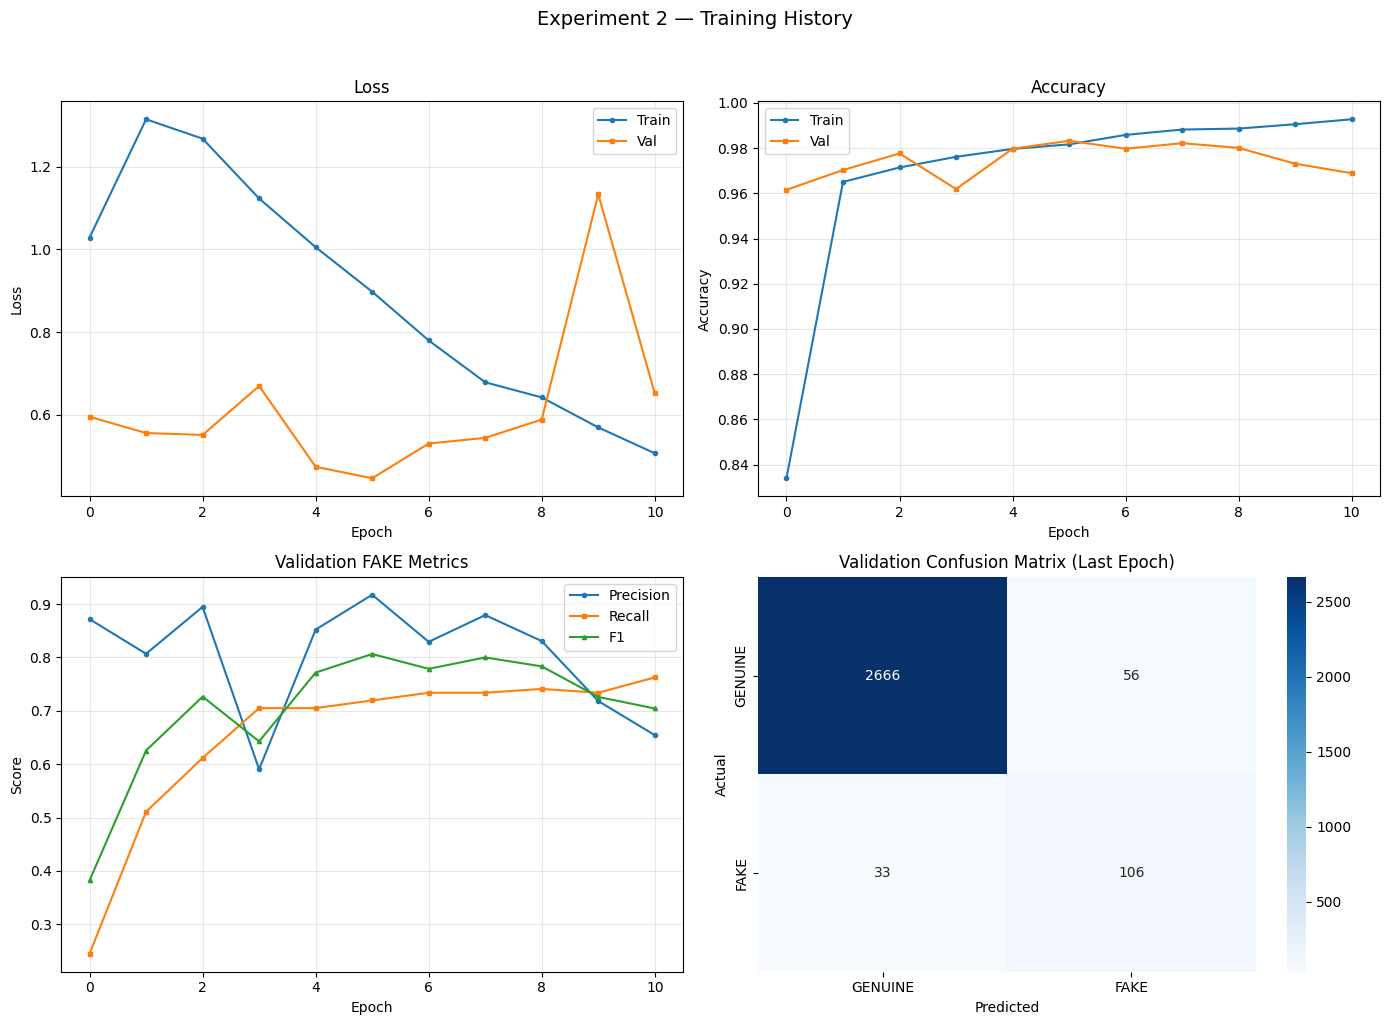

Best validation FAKE F1: 0.8065


In [22]:
# ============================================================
# SECTION 22: VALIDATION — TRAINING HISTORY
# ============================================================
# Run this after training is complete.

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Loss curves
axes[0, 0].plot(history["train_loss"], label="Train", marker="o", markersize=3)
axes[0, 0].plot(history["val_loss"], label="Val", marker="s", markersize=3)
axes[0, 0].set_title("Loss")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Accuracy curves
axes[0, 1].plot(history["train_acc"], label="Train", marker="o", markersize=3)
axes[0, 1].plot(history["val_acc"], label="Val", marker="s", markersize=3)
axes[0, 1].set_title("Accuracy")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Accuracy")
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# FAKE metrics
axes[1, 0].plot(history["val_fake_p"], label="Precision", marker="o", markersize=3)
axes[1, 0].plot(history["val_fake_r"], label="Recall", marker="s", markersize=3)
axes[1, 0].plot(history["val_fake_f1"], label="F1", marker="^", markersize=3)
axes[1, 0].set_title("Validation FAKE Metrics")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Score")
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Validation confusion matrix (last epoch)
cm = confusion_matrix(val_labels_all, val_preds_all)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[1, 1],
            xticklabels=["GENUINE", "FAKE"], yticklabels=["GENUINE", "FAKE"])
axes[1, 1].set_title("Validation Confusion Matrix (Last Epoch)")
axes[1, 1].set_xlabel("Predicted")
axes[1, 1].set_ylabel("Actual")

plt.suptitle("Experiment 2 — Training History", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

print(f"Best validation FAKE F1: {best_val_fake_f1:.4f}")

## 23. Checkpointing

Load the best model checkpoint saved during training. This ensures we evaluate the model that achieved the highest validation FAKE F1.

In [24]:
# ============================================================
# SECTION 23: LOAD BEST CHECKPOINT
# ============================================================
# Run this after training is complete.

# Load best model weights
model.load_state_dict(
    torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
)
model.eval()

print(f"Best model loaded from: {CHECKPOINT_PATH}")
print(f"Best validation FAKE F1: {best_val_fake_f1:.4f}")

Best model loaded from: C:\DEV\FAKE ML\Experiment_2\best_experiment2_model.pth
Best validation FAKE F1: 0.8065


## 24. Threshold Selection

**Why tune the threshold?**

The default classification threshold of 0.5 may not be optimal for the imbalanced fraud-detection task. By adjusting the threshold, we can trade off between catching more frauds (higher recall) and reducing false alarms (higher precision).

**Important**: Threshold tuning is performed on the **validation set only**. The test set must remain untouched during this process.

Strategy:
1. Collect FAKE probabilities from the model on the validation set.
2. Test thresholds from 0.30 to 0.70 in steps of 0.05.
3. Select the threshold that maximizes FAKE F1 on the validation set.
4. Apply the selected threshold once to the test set for final evaluation.

In [25]:
# ============================================================
# SECTION 24: THRESHOLD SELECTION (on VALIDATION set)
# ============================================================
# DO NOT tune threshold on the test set!

# Collect validation probabilities
val_probs_list = []
val_true_list = []

model.eval()
with torch.no_grad():
    for ids, mask, imgs, tfidf_b, bow_b, labels in val_loader:
        ids = ids.to(device)
        mask = mask.to(device)
        imgs = imgs.to(device)
        tfidf_b = tfidf_b.to(device)
        bow_b = bow_b.to(device)

        fusion_logits, _, _, _, _ = model(ids, mask, imgs, tfidf_b, bow_b)
        probs = torch.softmax(fusion_logits, dim=1)[:, 1]  # FAKE probability
        val_probs_list.extend(probs.cpu().numpy())
        val_true_list.extend(labels.numpy())

val_probs = np.array(val_probs_list)
val_true = np.array(val_true_list)

# Test different thresholds
thresholds = np.arange(0.30, 0.71, 0.05)
results = []

for thresh in thresholds:
    preds = (val_probs >= thresh).astype(int)
    p = precision_score(val_true, preds, zero_division=0)
    r = recall_score(val_true, preds, zero_division=0)
    f1 = f1_score(val_true, preds, zero_division=0)
    acc = accuracy_score(val_true, preds)
    tn, fp, fn, tp = confusion_matrix(val_true, preds).ravel()
    results.append({
        "Threshold": round(thresh, 2),
        "Accuracy": round(acc, 4),
        "FAKE_Prec": round(p, 4),
        "FAKE_Rec": round(r, 4),
        "FAKE_F1": round(f1, 4),
        "FP": fp, "FN": fn
    })

results_df = pd.DataFrame(results)
print("Threshold Analysis on Validation Set:")
display(results_df)

# Select best threshold
best_idx = results_df["FAKE_F1"].idxmax()
best_threshold = results_df.loc[best_idx, "Threshold"]
best_f1_val = results_df.loc[best_idx, "FAKE_F1"]

print(f"\n{'=' * 60}")
print(f"Selected threshold: {best_threshold:.2f}")
print(f"Validation FAKE F1 at this threshold: {best_f1_val:.4f}")
print(f"{'=' * 60}")
print(f"\nThis threshold will be applied to the test set in Section 25.")
print(f"DO NOT change this threshold based on test set results.")

Threshold Analysis on Validation Set:


,Threshold,Accuracy,FAKE_Prec,FAKE_Rec,FAKE_F1,FP,FN
0,0.30,0.9825,0.8938,0.7266,0.8016,12,38
1,0.35,0.9829,0.9018,0.7266,0.8048,11,38
2,0.40,0.9832,0.9099,0.7266,0.8080,10,38
3,0.45,0.9832,0.9099,0.7266,0.8080,10,38
4,0.50,0.9832,0.9174,0.7194,0.8065,9,39
5,0.55,0.9832,0.9174,0.7194,0.8065,9,39
6,0.60,0.9829,0.9167,0.7122,0.8016,9,40
7,0.65,0.9825,0.9159,0.7050,0.7967,9,41
8,0.70,0.9829,0.9327,0.6978,0.7984,7,42



Selected threshold: 0.40
Validation FAKE F1 at this threshold: 0.8080

This threshold will be applied to the test set in Section 25.
DO NOT change this threshold based on test set results.


## 25. Final Test Evaluation

**Only run this after training and threshold selection are complete.**

The test set has been completely untouched during:
- Model training
- Early stopping decisions
- Checkpoint selection
- Threshold tuning

Now we apply the best model with the selected threshold **once** on the held-out test set.

In [26]:
# ============================================================
# SECTION 25: FINAL TEST SET EVALUATION
# ============================================================
# Only run AFTER training + threshold selection.

test_probs_list = []
test_true_list = []

model.eval()
with torch.no_grad():
    for ids, mask, imgs, tfidf_b, bow_b, labels in test_loader:
        ids = ids.to(device)
        mask = mask.to(device)
        imgs = imgs.to(device)
        tfidf_b = tfidf_b.to(device)
        bow_b = bow_b.to(device)

        fusion_logits, _, _, _, _ = model(ids, mask, imgs, tfidf_b, bow_b)
        probs = torch.softmax(fusion_logits, dim=1)[:, 1]
        test_probs_list.extend(probs.cpu().numpy())
        test_true_list.extend(labels.numpy())

test_probs = np.array(test_probs_list)
test_true = np.array(test_true_list)
test_preds = (test_probs >= best_threshold).astype(int)

# Comprehensive metrics
print("=" * 60)
print("EXPERIMENT 2 — FINAL TEST SET EVALUATION")
print(f"Threshold: {best_threshold:.2f}")
print("=" * 60)

acc = accuracy_score(test_true, test_preds)
prec = precision_score(test_true, test_preds, zero_division=0)
rec = recall_score(test_true, test_preds, zero_division=0)
f1 = f1_score(test_true, test_preds, zero_division=0)
macro_f1 = f1_score(test_true, test_preds, average="macro", zero_division=0)
weighted_f1 = f1_score(test_true, test_preds, average="weighted", zero_division=0)

print(f"\nAccuracy:           {acc:.4f}")
print(f"Precision:          {prec:.4f}")
print(f"Recall:             {rec:.4f}")
print(f"F1:                 {f1:.4f}")
print(f"Macro F1:           {macro_f1:.4f}")
print(f"Weighted F1:        {weighted_f1:.4f}")

# Confusion matrix details
tn, fp, fn, tp = confusion_matrix(test_true, test_preds).ravel()
print(f"\n--- Confusion Matrix ---")
print(f"  True Negatives:  {tn}")
print(f"  False Positives: {fp}")
print(f"  False Negatives: {fn}")
print(f"  True Positives:  {tp}")

print(f"\n--- FAKE Class Focus ---")
print(f"  FAKE Precision:  {tp/(tp+fp):.4f}" if (tp+fp) > 0 else "  FAKE Precision: N/A")
print(f"  FAKE Recall:     {tp/(tp+fn):.4f}" if (tp+fn) > 0 else "  FAKE Recall: N/A")
print(f"  FAKE F1:         {f1:.4f}")
print(f"  False Negatives: {fn} (fraudulent jobs MISSED as genuine)")
print(f"  False Positives: {fp} (genuine jobs FLAGGED as fraud)")

print(f"\n--- Classification Report ---")
print(classification_report(
    test_true, test_preds,
    target_names=["GENUINE", "FAKE"],
    zero_division=0
))

EXPERIMENT 2 — FINAL TEST SET EVALUATION
Threshold: 0.40

Accuracy:           0.9824
Precision:          0.9508
Recall:             0.6705
F1:                 0.7864
Macro F1:           0.8886
Weighted F1:        0.9809

--- Confusion Matrix ---
  True Negatives:  3397
  False Positives: 6
  False Negatives: 57
  True Positives:  116

--- FAKE Class Focus ---
  FAKE Precision:  0.9508
  FAKE Recall:     0.6705
  FAKE F1:         0.7864
  False Negatives: 57 (fraudulent jobs MISSED as genuine)
  False Positives: 6 (genuine jobs FLAGGED as fraud)

--- Classification Report ---
              precision    recall  f1-score   support

     GENUINE       0.98      1.00      0.99      3403
        FAKE       0.95      0.67      0.79       173

    accuracy                           0.98      3576
   macro avg       0.97      0.83      0.89      3576
weighted avg       0.98      0.98      0.98      3576



## 26. Confusion Matrix — Visualized

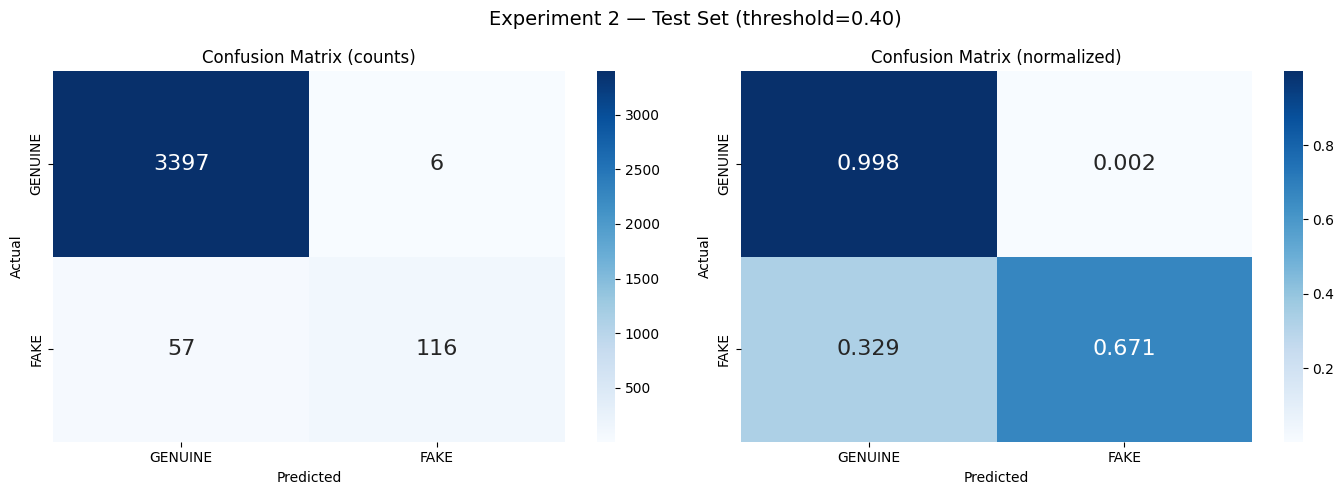

False Positives: 6 (GENUINE → FAKE)
False Negatives: 57 (FAKE → GENUINE)


In [27]:
# ============================================================
# SECTION 26: CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(test_true, test_preds)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion matrix heatmap
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["GENUINE", "FAKE"], yticklabels=["GENUINE", "FAKE"],
            annot_kws={"size": 16})
axes[0].set_title("Confusion Matrix (counts)")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# Normalized confusion matrix
cm_norm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm_norm, annot=True, fmt=".3f", cmap="Blues", ax=axes[1],
            xticklabels=["GENUINE", "FAKE"], yticklabels=["GENUINE", "FAKE"],
            annot_kws={"size": 16})
axes[1].set_title("Confusion Matrix (normalized)")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.suptitle(f"Experiment 2 — Test Set (threshold={best_threshold:.2f})", fontsize=14)
plt.tight_layout()
plt.show()

print(f"False Positives: {fp} (GENUINE → FAKE)")
print(f"False Negatives: {fn} (FAKE → GENUINE)")

## 27. Ablation Experiments

> **DO NOT execute automatically.** Run each ablation experiment manually.

Seven controlled experiments to determine which modalities contribute to fraud detection:

| Exp | Name | Modalities | Purpose |
|-----|------|-----------|---------|
| A | BERT Only | BERT | Semantic text understanding alone |
| B | TF-IDF Only | TF-IDF | Statistical text features alone |
| C | BoW Only | BoW | Binary lexical features alone |
| D | ResNet-50 Only | ResNet-50 | Pretrained image features alone |
| E | Text Only | BERT + TF-IDF + BoW | Text-only multimodal (no images) |
| F | Text + ResNet-50 | BERT + TF-IDF + ResNet-50 | Full without BoW |
| G | Full Multimodal | All four | Complete model

In [28]:
# ============================================================
# SECTION 27: ABLATION EXPERIMENTS
# ============================================================
# DO NOT execute automatically. Run each experiment manually.

ABLATION_CONFIGS = {
    "A_BERT_Only": {
        "use_bert": True, "use_tfidf": False,
        "use_bow": False, "use_resnet": False,
        "description": "BERT text branch only"
    },
    "B_TFIDF_Only": {
        "use_bert": False, "use_tfidf": True,
        "use_bow": False, "use_resnet": False,
        "description": "TF-IDF text branch only"
    },
    "C_BoW_Only": {
        "use_bert": False, "use_tfidf": False,
        "use_bow": True, "use_resnet": False,
        "description": "BoW text branch only"
    },
    "D_ResNet50_Only": {
        "use_bert": False, "use_tfidf": False,
        "use_bow": False, "use_resnet": True,
        "description": "Pretrained ResNet-50 image branch only"
    },
    "E_Text_Only": {
        "use_bert": True, "use_tfidf": True,
        "use_bow": True, "use_resnet": False,
        "description": "All text branches (no images)"
    },
    "F_Text_Plus_ResNet": {
        "use_bert": True, "use_tfidf": True,
        "use_bow": False, "use_resnet": True,
        "description": "BERT + TF-IDF + ResNet-50 (no BoW)"
    },
    "G_Full_Multimodal": {
        "use_bert": True, "use_tfidf": True,
        "use_bow": True, "use_resnet": True,
        "description": "Full multimodal model (all branches)"
    }
}

print("Ablation configurations defined:")
for name, cfg in ABLATION_CONFIGS.items():
    branches = []
    if cfg["use_bert"]: branches.append("BERT")
    if cfg["use_tfidf"]: branches.append("TF-IDF")
    if cfg["use_bow"]: branches.append("BoW")
    if cfg["use_resnet"]: branches.append("ResNet-50")
    print(f"  {name:22s}: {' + '.join(branches):30s} ({cfg['description']})")

Ablation configurations defined:
  A_BERT_Only           : BERT                           (BERT text branch only)
  B_TFIDF_Only          : TF-IDF                         (TF-IDF text branch only)
  C_BoW_Only            : BoW                            (BoW text branch only)
  D_ResNet50_Only       : ResNet-50                      (Pretrained ResNet-50 image branch only)
  E_Text_Only           : BERT + TF-IDF + BoW            (All text branches (no images))
  F_Text_Plus_ResNet    : BERT + TF-IDF + ResNet-50      (BERT + TF-IDF + ResNet-50 (no BoW))
  G_Full_Multimodal     : BERT + TF-IDF + BoW + ResNet-50 (Full multimodal model (all branches))


In [29]:
# ============================================================
# ABLATION MODEL CLASS
# ============================================================
# Configurable model that enables/disables branches.

class AblationClassifier(nn.Module):
    '''Configurable classifier for ablation experiments.

    Enables only the specified branches and adjusts fusion dimension.
    '''

    def __init__(self, bert, resnet, use_bert=True, use_tfidf=True,
                 use_bow=True, use_resnet=True, dropout_rate=DROPOUT_RATE):
        super().__init__()
        self.use_bert = use_bert
        self.use_tfidf = use_tfidf
        self.use_bow = use_bow
        self.use_resnet = use_resnet
        self.bert = bert
        self.resnet = resnet

        fusion_dim = 0

        if use_bert:
            fusion_dim += BERT_PROJ_DIM
            self.bert_proj = nn.Sequential(
                nn.Linear(BERT_OUT_DIM, BERT_PROJ_DIM), nn.ReLU(),
                nn.BatchNorm1d(BERT_PROJ_DIM), nn.Dropout(dropout_rate))
            self.bert_clf = nn.Linear(BERT_PROJ_DIM, 2)

        if use_tfidf:
            fusion_dim += TFIDF_PROJ_DIM
            self.tfidf_proj = nn.Sequential(
                nn.Linear(TFIDF_MAX_FEATURES, TFIDF_PROJ_DIM), nn.ReLU(),
                nn.BatchNorm1d(TFIDF_PROJ_DIM), nn.Dropout(dropout_rate))
            self.tfidf_clf = nn.Linear(TFIDF_PROJ_DIM, 2)

        if use_bow:
            fusion_dim += BOW_PROJ_DIM
            self.bow_proj = nn.Sequential(
                nn.Linear(BOW_MAX_FEATURES, BOW_PROJ_DIM), nn.ReLU(),
                nn.BatchNorm1d(BOW_PROJ_DIM), nn.Dropout(dropout_rate))
            self.bow_clf = nn.Linear(BOW_PROJ_DIM, 2)

        if use_resnet:
            fusion_dim += IMG_PROJ_DIM
            self.img_proj = nn.Sequential(
                nn.Linear(RESNET_OUT_DIM, IMG_PROJ_DIM), nn.ReLU(),
                nn.BatchNorm1d(IMG_PROJ_DIM), nn.Dropout(dropout_rate))
            self.img_clf = nn.Linear(IMG_PROJ_DIM, 2)

        self.fusion = nn.Sequential(
            nn.Linear(fusion_dim, 512), nn.ReLU(),
            nn.BatchNorm1d(512), nn.Dropout(dropout_rate),
            nn.Linear(512, 256), nn.ReLU(),
            nn.BatchNorm1d(256), nn.Dropout(dropout_rate),
            nn.Linear(256, 2))

    def forward(self, input_ids, attention_mask, images, tfidf_feats, bow_feats):
        features = []
        logits = {}

        if self.use_bert:
            with torch.no_grad():
                bert_out = self.bert(input_ids=input_ids, attention_mask=attention_mask)
            bert_p = self.bert_proj(bert_out.pooler_output)
            features.append(bert_p)
            logits["bert"] = self.bert_clf(bert_p)

        if self.use_tfidf:
            tfidf_p = self.tfidf_proj(tfidf_feats)
            features.append(tfidf_p)
            logits["tfidf"] = self.tfidf_clf(tfidf_p)

        if self.use_bow:
            bow_p = self.bow_proj(bow_feats)
            features.append(bow_p)
            logits["bow"] = self.bow_clf(bow_p)

        if self.use_resnet:
            img_p = self.img_proj(self.resnet(images))
            features.append(img_p)
            logits["img"] = self.img_clf(img_p)

        combined = torch.cat(features, dim=1)
        logits["fusion"] = self.fusion(combined)
        return logits

print("AblationClassifier defined.")

AblationClassifier defined.


In [30]:
# ============================================================
# ABLATION TRAINING FUNCTION
# ============================================================

def run_ablation(config_name, config, num_epochs=10):
    '''Train and evaluate an ablation model.

    Args:
        config_name: Name of the ablation experiment
        config: Dict with use_bert, use_tfidf, use_bow, use_resnet flags
        num_epochs: Number of training epochs

    Returns:
        dict with validation metrics
    '''
    print(f"\n{'=' * 60}")
    print(f"ABLATION: {config_name}")
    print(f"Description: {config['description']}")
    print(f"{'=' * 60}")

    # Create fresh BERT and ResNet-50
    bert_clone = BertModel.from_pretrained(BERT_MODEL_NAME)
    for p in bert_clone.parameters():
        p.requires_grad = False

    resnet_clone = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    for p in resnet_clone.parameters():
        p.requires_grad = False
    resnet_clone.fc = nn.Identity()

    abl_model = AblationClassifier(
        bert_clone, resnet_clone,
        use_bert=config["use_bert"],
        use_tfidf=config["use_tfidf"],
        use_bow=config["use_bow"],
        use_resnet=config["use_resnet"]
    ).to(device)

    # Only optimize trainable parameters
    trainable = [p for p in abl_model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(trainable, lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

    best_f1 = 0.0
    best_preds, best_labels = None, None

    for epoch in range(num_epochs):
        abl_model.train()
        for ids, mask, imgs, tfidf_b, bow_b, labels in train_loader:
            ids, mask = ids.to(device), mask.to(device)
            imgs = imgs.to(device)
            tfidf_b, bow_b = tfidf_b.to(device), bow_b.to(device)
            labels = labels.to(device)

            opt.zero_grad()
            out = abl_model(ids, mask, imgs, tfidf_b, bow_b)
            loss = criterion(out["fusion"], labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(abl_model.parameters(), max_norm=1.0)
            opt.step()

        # Validate
        abl_model.eval()
        v_preds, v_labels = [], []
        with torch.no_grad():
            for ids, mask, imgs, tfidf_b, bow_b, labels in val_loader:
                ids, mask = ids.to(device), mask.to(device)
                imgs = imgs.to(device)
                tfidf_b, bow_b = tfidf_b.to(device), bow_b.to(device)
                out = abl_model(ids, mask, imgs, tfidf_b, bow_b)
                preds = torch.argmax(out["fusion"], dim=1)
                v_preds.extend(preds.cpu().numpy())
                v_labels.extend(labels.numpy())

        f1 = f1_score(v_labels, v_preds, pos_label=1, zero_division=0)
        rec = recall_score(v_labels, v_preds, pos_label=1, zero_division=0)
        if f1 > best_f1:
            best_f1 = f1
            best_preds = np.array(v_preds)
            best_labels = np.array(v_labels)

        print(f"  Epoch {epoch+1}/{num_epochs}: Val FAKE F1={f1:.4f}, Recall={rec:.4f}")

    # Final metrics at best F1
    if best_preds is not None:
        tn, fp, fn, tp = confusion_matrix(best_labels, best_preds).ravel()
        print(f"\n  Best Val FAKE F1:  {best_f1:.4f}")
        print(f"  False Negatives:   {fn}")
        print(f"  False Positives:   {fp}")

    return {"name": config_name, "best_val_f1": best_f1, "fn": fn if best_preds is not None else None}

print("run_ablation() function defined.")
print("\nTo run an ablation experiment:")
print("  result = run_ablation('A_BERT_Only', ABLATION_CONFIGS['A_BERT_Only'], num_epochs=10)")

run_ablation() function defined.

To run an ablation experiment:
  result = run_ablation('A_BERT_Only', ABLATION_CONFIGS['A_BERT_Only'], num_epochs=10)


## 28. Custom Prediction

Test the model with your own job posting image and text. Provides both the fusion prediction and branch-level analysis.

In [31]:
# ============================================================
# SECTION 28: CUSTOM PREDICTION
# ============================================================
# Provide your own job posting image and text for prediction.

def predict_custom(image_path, job_text, threshold=None):
    '''Predict whether a job posting is GENUINE or FAKE.

    Args:
        image_path: Path to the job screenshot image
        job_text: Full job posting text (combined fields)
        threshold: Classification threshold (default: selected threshold)

    Returns:
        dict with prediction, confidence, and branch-level analysis
    '''
    if threshold is None:
        threshold = best_threshold

    model.eval()

    # BERT tokenization
    encoding = tokenizer(
        job_text, truncation=True, padding="max_length",
        max_length=BERT_MAX_LEN, return_tensors="pt"
    )
    input_ids = encoding["input_ids"].to(device)
    attention_mask = encoding["attention_mask"].to(device)

    # TF-IDF features
    tfidf_feat = torch.FloatTensor(
        tfidf_vectorizer.transform([job_text]).toarray()
    ).to(device)

    # BoW features
    bow_feat = torch.FloatTensor(
        bow_vectorizer.transform([job_text]).toarray()
    ).to(device)

    # Image
    try:
        image = Image.open(image_path).convert("RGB")
        image = val_test_transform(image).unsqueeze(0).to(device)
    except Exception as e:
        print(f"Warning: Could not load image ({e}). Using gray placeholder.")
        image = torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE).to(device)

    # Inference
    with torch.no_grad():
        fusion_logits, bert_logits, tfidf_logits, bow_logits, img_logits = model(
            input_ids, attention_mask, image, tfidf_feat, bow_feat
        )
        fusion_probs = torch.softmax(fusion_logits, dim=1)[0]
        bert_probs = torch.softmax(bert_logits, dim=1)[0]
        tfidf_probs = torch.softmax(tfidf_logits, dim=1)[0]
        bow_probs = torch.softmax(bow_logits, dim=1)[0]
        img_probs = torch.softmax(img_logits, dim=1)[0]

    fake_prob = fusion_probs[1].item()
    prediction = "FAKE" if fake_prob >= threshold else "GENUINE"
    confidence = fake_prob if prediction == "FAKE" else fusion_probs[0].item()

    # Branch analysis
    branches = {
        "BERT":     bert_probs[1].item(),
        "TF-IDF":   tfidf_probs[1].item(),
        "BoW":      bow_probs[1].item(),
        "ResNet-50": img_probs[1].item(),
    }

    # Print results
    print("\n" + "=" * 60)
    print("CUSTOM JOB POSTING PREDICTION")
    print("=" * 60)
    print(f"Prediction:    {prediction}")
    print(f"Confidence:    {confidence * 100:.2f}%")
    print(f"FAKE prob:     {fake_prob * 100:.2f}%")
    print(f"GENUINE prob:  {fusion_probs[0].item() * 100:.2f}%")
    print(f"Threshold:     {threshold:.2f}")
    print("-" * 60)
    print("Branch-Level Analysis:")
    for branch, prob in branches.items():
        pred = "FAKE" if prob >= 0.5 else "GENUINE"
        print(f"  {branch:12s}: {pred:8s} (FAKE prob: {prob*100:.2f}%)")
    print("=" * 60)

    return {
        "prediction": prediction,
        "confidence": confidence,
        "fake_probability": fake_prob,
        "genuine_probability": fusion_probs[0].item(),
        "threshold_used": threshold,
        "branch_probabilities": branches
    }

print("predict_custom() defined.")
print("\nUsage:")
print("  result = predict_custom('path/to/image.png', 'Your job description text here...')")
print("  print(result)")

predict_custom() defined.

Usage:
  result = predict_custom('path/to/image.png', 'Your job description text here...')
  print(result)


In [32]:
# ============================================================
# EXAMPLE: Predict from dataset
# ============================================================
# Uncomment and modify the index to test different job postings.

# Test a known GENUINE posting
# idx = 0  # change to any row index
# sample_row = test_df.iloc[idx]
# result = predict_custom(
#     sample_row["webpage_screenshot"],
#     sample_row["text"]
# )
# print(f"\nActual label: {CLASS_NAMES[sample_row['fraudulent']]}")

# Test a known FAKE posting
# fake_idx = test_df[test_df["fraudulent"] == 1].index[0]
# fake_row = test_df.loc[fake_idx]
# result = predict_custom(
#     fake_row["webpage_screenshot"],
#     fake_row["text"]
# )
# print(f"\nActual label: {CLASS_NAMES[fake_row['fraudulent']]}")

print("Uncomment the cells above to test predictions on dataset samples.")

Uncomment the cells above to test predictions on dataset samples.


## 29. Experiment 1 vs Experiment 2 Comparison

> **DO NOT fill in Experiment 2 values until you have run the test evaluation.**

Experiment 1 values are from the completed Experiment 1 run. Experiment 2 values will be populated after you run Section 25.

In [33]:
# ============================================================
# SECTION 29: EXPERIMENT 1 vs EXPERIMENT 2 COMPARISON
# ============================================================

# Experiment 1 results (from completed run)
EXP1 = {
    "Accuracy":      0.9743,
    "Precision":     0.7120,
    "FAKE Recall":   0.7861,
    "FAKE F1":       0.7473,
    "Macro F1":      0.8700,   # from classification report macro avg
    "Weighted F1":   0.9700,   # from classification report weighted avg
    "False Positives": 55,
    "False Negatives": 37,
}

# Experiment 2 results — FILL AFTER RUNNING SECTION 25
EXP2 = {
    "Accuracy":       acc if "acc" in dir() else "TODO",
    "Precision":      prec if "prec" in dir() else "TODO",
    "FAKE Recall":    rec if "rec" in dir() else "TODO",
    "FAKE F1":        f1 if "f1" in dir() else "TODO",
    "Macro F1":       macro_f1 if "macro_f1" in dir() else "TODO",
    "Weighted F1":    weighted_f1 if "weighted_f1" in dir() else "TODO",
    "False Positives": fp if "fp" in dir() else "TODO",
    "False Negatives": fn if "fn" in dir() else "TODO",
}

comparison = pd.DataFrame({
    "Metric": list(EXP1.keys()),
    "Experiment 1": list(EXP1.values()),
    "Experiment 2": list(EXP2.values())
})

print("=" * 60)
print("EXPERIMENT 1 vs EXPERIMENT 2 COMPARISON")
print("=" * 60)
display(comparison)

print("\nKey comparison metrics (in order of importance):")
print("  1. FAKE Recall:    Does Experiment 2 catch more fraudulent jobs?")
print("  2. FAKE F1:        Is the precision-recall balance better?")
print("  3. False Negatives: Are fewer fraudulent jobs missed?")
print("  4. Accuracy:       Secondary — high accuracy is expected due to imbalance")
print("\nNOTE: Experiment 2 values are placeholders until you run the evaluation.")

EXPERIMENT 1 vs EXPERIMENT 2 COMPARISON


,Metric,Experiment 1,Experiment 2
0,Accuracy,0.9743,0.982383
1,Precision,0.7120,0.950820
2,FAKE Recall,0.7861,0.670520
3,FAKE F1,0.7473,0.786441
4,Macro F1,0.8700,0.888626
5,Weighted F1,0.9700,0.980925
6,False Positives,55.0000,6.000000
7,False Negatives,37.0000,57.000000



Key comparison metrics (in order of importance):
  1. FAKE Recall:    Does Experiment 2 catch more fraudulent jobs?
  2. FAKE F1:        Is the precision-recall balance better?
  3. False Negatives: Are fewer fraudulent jobs missed?
  4. Accuracy:       Secondary — high accuracy is expected due to imbalance

NOTE: Experiment 2 values are placeholders until you run the evaluation.


## 30. Final Findings

### Summary

This notebook implements Experiment 2 of the job-posting fraud detection research project, with two key improvements over Experiment 1:

1. **Pretrained ResNet-50 image backbone** — Replaces the custom Multi-Kernel ResNet with a standard pretrained ResNet-50 using transfer learning. This provides stronger, more generalizable image features from ImageNet pretraining.

2. **Proper validation split** — Fixes the critical bug where the validation DataLoader reused the training dataset. Now uses a genuine three-way stratified split (train/validation/test).

### Research Question

> **Does replacing the custom Multi-Kernel ResNet image branch with a pretrained ResNet-50 transfer-learning branch improve fraudulent-job detection, particularly FAKE recall and FAKE F1, while maintaining strong overall performance?**

### How to Interpret Results

After running the notebook, compare Experiment 2 against Experiment 1 on the following:

| What to check | Good sign | Bad sign |
|---------------|-----------|----------|
| FAKE Recall | Higher than 0.7861 | Lower than 0.7861 |
| FAKE F1 | Higher than 0.7473 | Lower than 0.7473 |
| False Negatives | Fewer than 37 | More than 37 |
| Accuracy | Maintained or improved | Significantly dropped |

### Files Created

| File | Description |
|------|-------------|
| `Experiment_2_Multimodal_ResNet50.ipynb` | Main experiment notebook |
| `flow.md` | Complete Experiment 2 flow documentation |
| `decision.md` | Architectural and methodological decision log |
| `best_experiment2_model.pth` | Best model checkpoint (after training) |

### Next Steps (if needed)

1. If Phase A (frozen backbone) is insufficient → try Phase B (unfreeze layer3+layer4)
2. Run ablation experiments to understand modality contributions
3. Consider focal loss if weighted CE is insufficient
4. Test with the synthetic Flipkart screenshot to compare with Experiment 1
5. Write up findings for the research report

In [36]:
# ============================================================
# EXPERIMENT 2: MANUAL TESTING
# Job Description + Screenshot Image
# ============================================================

def predict_manual(image_path, job_description, threshold=None):

    # --------------------------------------------------------
    # Use the threshold selected from the validation set
    # --------------------------------------------------------
    if threshold is None:
        threshold = best_threshold

    # --------------------------------------------------------
    # Check image path
    # --------------------------------------------------------
    if not os.path.exists(image_path):
        raise FileNotFoundError(
            f"Image not found:\n{image_path}"
        )

    # --------------------------------------------------------
    # Evaluation mode
    # --------------------------------------------------------
    model.eval()

    # ========================================================
    # 1. BERT
    # ========================================================

    encoding = tokenizer(
        job_description,
        truncation=True,
        padding="max_length",
        max_length=BERT_MAX_LEN,
        return_tensors="pt"
    )

    input_ids = encoding["input_ids"].to(device)
    attention_mask = encoding["attention_mask"].to(device)

    # ========================================================
    # 2. TF-IDF
    # ========================================================

    tfidf_feat = torch.FloatTensor(
        tfidf_vectorizer.transform(
            [job_description]
        ).toarray()
    ).to(device)

    # ========================================================
    # 3. BoW
    # ========================================================

    bow_feat = torch.FloatTensor(
        bow_vectorizer.transform(
            [job_description]
        ).toarray()
    ).to(device)

    # ========================================================
    # 4. IMAGE
    # ========================================================

    image = Image.open(image_path).convert("RGB")

    image = val_test_transform(image)
    image = image.unsqueeze(0).to(device)

    # ========================================================
    # 5. MODEL INFERENCE
    # ========================================================

    with torch.no_grad():

        (
            fusion_logits,
            bert_logits,
            tfidf_logits,
            bow_logits,
            img_logits
        ) = model(
            input_ids,
            attention_mask,
            image,
            tfidf_feat,
            bow_feat
        )

        # Fusion prediction
        fusion_probs = torch.softmax(
            fusion_logits, dim=1
        )[0]

        # Individual branch predictions
        bert_probs = torch.softmax(
            bert_logits, dim=1
        )[0]

        tfidf_probs = torch.softmax(
            tfidf_logits, dim=1
        )[0]

        bow_probs = torch.softmax(
            bow_logits, dim=1
        )[0]

        img_probs = torch.softmax(
            img_logits, dim=1
        )[0]

    # ========================================================
    # 6. FINAL PREDICTION
    # ========================================================

    fake_probability = fusion_probs[1].item()
    genuine_probability = fusion_probs[0].item()

    if fake_probability >= threshold:
        prediction = "FAKE"
        confidence = fake_probability
    else:
        prediction = "GENUINE"
        confidence = genuine_probability

    # ========================================================
    # 7. BRANCH-LEVEL ANALYSIS
    # ========================================================

    branch_results = {
        "BERT": bert_probs[1].item(),
        "TF-IDF": tfidf_probs[1].item(),
        "BoW": bow_probs[1].item(),
        "ResNet-50": img_probs[1].item()
    }

    # ========================================================
    # 8. DISPLAY RESULTS
    # ========================================================

    print("\n")
    print("=" * 65)
    print("          EXPERIMENT 2 — MANUAL PREDICTION")
    print("=" * 65)

    print(f"\nPrediction       : {prediction}")
    print(f"Confidence       : {confidence * 100:.2f}%")

    print("\nFusion Probabilities:")
    print(f"  GENUINE        : {genuine_probability * 100:.2f}%")
    print(f"  FAKE           : {fake_probability * 100:.2f}%")

    print(f"\nThreshold Used   : {threshold:.2f}")

    print("\n" + "-" * 65)
    print("Branch-Level Analysis")
    print("-" * 65)

    for branch, fake_prob in branch_results.items():

        branch_prediction = (
            "FAKE" if fake_prob >= 0.5
            else "GENUINE"
        )

        print(
            f"{branch:<15}: "
            f"{branch_prediction:<8} "
            f"(FAKE probability: {fake_prob * 100:.2f}%)"
        )

    print("=" * 65)

    # ========================================================
    # 9. RETURN RESULTS
    # ========================================================

    return {
        "prediction": prediction,
        "confidence": confidence,
        "genuine_probability": genuine_probability,
        "fake_probability": fake_probability,
        "threshold": threshold,
        "branch_probabilities": branch_results
    }


print("Manual prediction function is ready.")

Manual prediction function is ready.


In [37]:
# ============================================================
# ENTER YOUR JOB POSTING HERE
# ============================================================

job_description = """
APPLY https://Inkd.in/ezapDGiK

Tech Mahindra is Providing Internship Opportunities
Across Bhubaneswar!

+ Join Tech Mahindra's Internship Program and
learn from experienced professionals while building a
strong foundation for your future career.

Internship Opportunities Across Bhubaneswar
Open for Students & Freshers
Work on Real-World Industry Projects
Learn from Industry Experts
Build In-Demand Technical & Professional Skills
Certificate of Completion & Practical Exposure
Stipend-Based Opportunities (Performance
Based)

Take the first step toward a successful tech career
and gain valuable industry experience with Tech
Mahindra.

Comment "INTERESTED" to get the application
link!
"""

# ============================================================
# ENTER YOUR IMAGE PATH
# ============================================================

image_path = r"C:\Users\subha\Downloads\Mahindra.jpeg"

# ============================================================
# RUN PREDICTION
# ============================================================

result = predict_manual(
    image_path=image_path,
    job_description=job_description
)



          EXPERIMENT 2 — MANUAL PREDICTION

Prediction       : GENUINE
Confidence       : 99.97%

Fusion Probabilities:
  GENUINE        : 99.97%
  FAKE           : 0.03%

Threshold Used   : 0.40

-----------------------------------------------------------------
Branch-Level Analysis
-----------------------------------------------------------------
BERT           : GENUINE  (FAKE probability: 2.02%)
TF-IDF         : GENUINE  (FAKE probability: 1.26%)
BoW            : GENUINE  (FAKE probability: 0.11%)
ResNet-50      : GENUINE  (FAKE probability: 0.03%)
